# 15. Классификация временных рядов

Рабочий ноутбук к главе книги `../chapters/15-classification.md`: здесь только задания и код, теория и выводы — в главе. Источник — глава 29 пособия.

Графики для главы сохраняй через `save_fig(fig, "имя")` → `../chapters/img/15-имя.png`.

In [1]:
import logging
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Глушим шум до импорта ETNA: FutureWarning из pandas и предупреждение tqdm про ipywidgets
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from tsfresh.feature_extraction.settings import MinimalFCParameters

from etna.datasets import TSDataset
from etna.experimental.classification import TimeSeriesBinaryClassifier
from etna.experimental.classification.feature_extraction import TSFreshFeatureExtractor, WEASELFeatureExtractor

logging.getLogger("tsfresh").setLevel(logging.ERROR)

DATA_DIR = "../local/data"
IMG_DIR = "../chapters/img"  # графики для главы книги
RANDOM_SEED = 42


def save_fig(fig, name: str) -> None:
    """Сохранить график для главы книги: ../chapters/img/15-<name>.png."""
    os.makedirs(IMG_DIR, exist_ok=True)
    fig.savefig(f"{IMG_DIR}/15-{name}.png", dpi=150, bbox_inches="tight")


def make_classifier(features: str) -> TimeSeriesBinaryClassifier:
    """Классификатор рядов: признаки tsfresh или WEASEL + логистическая регрессия."""
    if features == "tsfresh":
        extractor = TSFreshFeatureExtractor(default_fc_parameters=MinimalFCParameters(), disable_progressbar=True)
    else:
        extractor = WEASELFeatureExtractor(
            padding_value="back_fill",
            window_sizes=[0.2, 0.3, 0.5, 0.7, 0.9],  # окна в долях длины ряда, как в пособии
            window_steps=[0.1, 0.15, 0.25, 0.35, 0.45],
            strategy="normal",  # со стратегией по умолчанию "entropy" на синтетике падает с ошибкой
        )
    return TimeSeriesBinaryClassifier(feature_extractor=extractor, classifier=LogisticRegression(max_iter=1000))


def crossval(features: str, x: list, y: np.ndarray, mask: np.ndarray) -> pd.Series:
    """Кросс-валидация с новым классификатором на каждом фолде: вероятность класса 1 для каждого ряда вне обучения.

    Не masked_crossval_score: с WEASEL он даёт утечку, см. шаг 1.3.
    """
    proba = np.zeros(len(y))
    for fold in np.unique(mask):
        test = mask == fold
        clf = make_classifier(features)
        clf.fit([s for s, t in zip(x, test) if not t], y[~test])
        proba[test] = clf.predict_proba([s for s, t in zip(x, test) if t])
    return pd.Series(proba)


def scores(y: np.ndarray, proba: pd.Series, mask: np.ndarray) -> dict:
    """AUC и доля верных ответов (порог 0.5), средние по фолдам."""
    auc = [roc_auc_score(y[mask == f], proba[mask == f]) for f in np.unique(mask)]
    acc = [accuracy_score(y[mask == f], proba[mask == f] > 0.5) for f in np.unique(mask)]
    return {"auc": round(float(np.mean(auc)), 2), "accuracy": round(float(np.mean(acc)), 2)}

## Задание 1. Синтетика: два набора классов

Классы, которые мы задали сами: какой способ признаков их различит.

### Шаг 1.1. Два набора

`pattern`: недельный узор против тех же значений, перемешанных по дням. `noise`: тихий шум против громкого. В каждом наборе по 100 рядов каждого класса, 12 недель, уровень ряда случайный от 50 до 200.

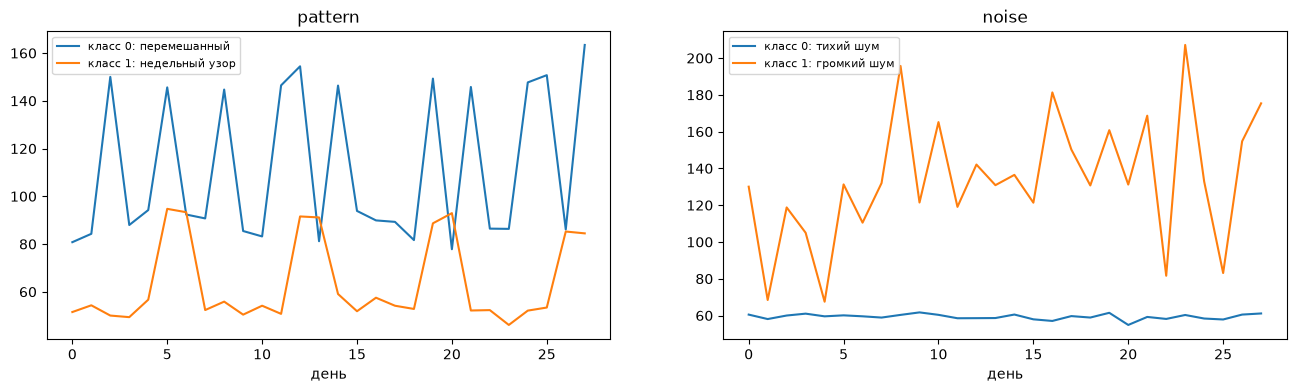

In [2]:
# Два набора по 200 рядов (по 100 каждого класса), 12 недель, уровень у каждого ряда свой — от 50 до 200:
#   pattern — класс 1: недельный узор (выходные выше будней); класс 0: те же значения, перемешанные по дням
#   noise   — класс 0: тихий шум ±3% от уровня; класс 1: громкий шум ±30%
N_PER_CLASS = 100
PERIODS = 12 * 7
rng = np.random.RandomState(RANDOM_SEED)
weekend = np.arange(PERIODS) % 7 >= 5  # ряды начинаются с понедельника


def weekly(level):
    return level * (1 + np.where(weekend, 0.4, -0.16) + rng.normal(0, 0.05, PERIODS))


GENERATORS = {
    "pattern": (lambda level: rng.permutation(weekly(level)), weekly),
    "noise": (lambda level: level * (1 + rng.normal(0, 0.03, PERIODS)), lambda level: level * (1 + rng.normal(0, 0.3, PERIODS))),
}
synthetic = {}
for name, (make_0, make_1) in GENERATORS.items():
    x = [make_0(rng.uniform(50, 200)) for _ in range(N_PER_CLASS)] + [make_1(rng.uniform(50, 200)) for _ in range(N_PER_CLASS)]
    y = np.array([0] * N_PER_CLASS + [1] * N_PER_CLASS)
    synthetic[name] = (x, y)

# По одному ряду каждого класса, первые 4 недели
CLASS_NAMES = {"pattern": ["перемешанный", "недельный узор"], "noise": ["тихий шум", "громкий шум"]}
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for ax, (name, (x, y)) in zip(axes, synthetic.items()):
    for cls, idx in enumerate([0, N_PER_CLASS]):
        ax.plot(x[idx][:28], label=f"класс {cls}: {CLASS_NAMES[name][cls]}")
    ax.set_title(name)
    ax.set_xlabel("день")
    ax.legend(loc="upper left", fontsize=8)
save_fig(fig, "synthetic")

#### Выводы

- **`pattern`:** у классов одинаковые значения, разный только порядок дней. Среднее, разброс, минимум и максимум у пары «ряд — его перемешанная копия» совпадают точно.
- **`noise`:** форма одна — шум без узора, разный только размах: ±3% и ±30% от уровня.

### Шаг 1.2. Два способа признаков

`TimeSeriesBinaryClassifier` с `TSFreshFeatureExtractor` (минимальный набор статистик) и с `WEASELFeatureExtractor`, классификатор — `LogisticRegression`. Кросс-валидация на 5 фолдах — своей функцией `crossval`, почему — в шаге 1.3.

In [3]:
# 5 фолдов; в каждом поровну рядов обоих классов
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
synthetic_scores = []
for name, (x, y) in synthetic.items():
    mask = np.zeros(len(y))
    for fold, (_, test) in enumerate(folds.split(x, y)):
        mask[test] = fold
    for features in ["tsfresh", "weasel"]:
        synthetic_scores.append({"dataset": name, "features": features, **scores(y, crossval(features, x, y, mask), mask)})
pd.DataFrame(synthetic_scores)

,dataset,features,auc,accuracy
0,pattern,tsfresh,0.42,0.44
1,pattern,weasel,1.00,1.00
2,noise,tsfresh,1.00,1.00
3,noise,weasel,0.51,0.53


#### Выводы

| набор | `tsfresh` | `weasel` |
|---|---|---|
| `pattern` — узор против перемешанного | 0.42 | **1.00** |
| `noise` — тихий шум против громкого | **1.00** | 0.51 |

(AUC; 0.5 — угадывание монеткой, 1 — без ошибок)

- **Каждый способ безошибочно решил одну задачу и провалил другую.**
- **tsfresh не видит порядок дней:** минимальный набор — среднее, разброс, минимум, максимум — у перемешанного ряда тот же, что у исходного.
- **WEASEL не видит масштаб:** перед подсчётом форм он нормирует каждый кусочек ряда, и тихий шум становится неотличим от громкого.
- **Вывод:** способ признаков выбирают под задачу — чем различаются классы: формой или величиной.

### Шаг 1.3. Проверка на шуме

Ряды — чистый шум, метки — случайные. Честная оценка должна дать AUC около 0.5. Сравниваем `masked_crossval_score` из ETNA и `crossval` с новым классификатором на каждом фолде.

In [4]:
# Ряды — чистый шум, метки — случайные: честный классификатор угадывает не лучше монетки (AUC около 0.5)
x_noise = [rng.normal(size=PERIODS) for _ in range(2 * N_PER_CLASS)]
y_noise = rng.permutation(np.array([0] * N_PER_CLASS + [1] * N_PER_CLASS))
mask_noise = np.zeros(len(y_noise))
for fold, (_, test) in enumerate(folds.split(x_noise, y_noise)):
    mask_noise[test] = fold

leak = make_classifier("weasel")
etna_auc = leak.masked_crossval_score(x=x_noise, y=y_noise, mask=mask_noise)["AUC"]
honest_proba = crossval("weasel", x_noise, y_noise, mask_noise)
honest_auc = [roc_auc_score(y_noise[mask_noise == f], honest_proba[mask_noise == f]) for f in range(5)]
pd.DataFrame({"masked_crossval_score": etna_auc, "crossval": honest_auc}, index=pd.Index(range(1, 6), name="fold")).round(2)

,masked_crossval_score,crossval
fold,,
1,0.56,0.56
2,0.89,0.40
3,0.86,0.63
4,0.87,0.57
5,0.85,0.64


In [5]:
# Почему так: экстрактор WEASEL при новом fit не забывает старые признаки, а дописывает к ним новые.
# Признаки, отобранные на прошлых фолдах, видели метки нынешнего тестового фолда — это утечка
print("слов-признаков у экстрактора после 5 фолдов:", len(leak.feature_extractor.weasel._vocabulary))
fresh = make_classifier("weasel").fit(x_noise, y_noise)
print("слов-признаков у нового экстрактора после одного fit:", len(fresh.feature_extractor.weasel._vocabulary))

слов-признаков у экстрактора после 5 фолдов: 282
слов-признаков у нового экстрактора после одного fit: 60


#### Выводы

- **`masked_crossval_score` с WEASEL «нашёл» закономерность в чистом шуме:** AUC 0.85–0.89 на фолдах 2–5. На первом фолде 0.56 — как и у честной проверки.
- **Причина — утечка:** метод обучает один и тот же экстрактор на каждом фолде, а экстрактор WEASEL копит признаки: после 5 фолдов у него 282 слова вместо 60. Слова, отобранные на прошлых фолдах, уже видели метки нынешнего тестового фолда.
- **`crossval` даёт 0.40–0.64** — около 0.5, как и должно быть на шуме. Разброс — от малого числа рядов в фолде (40).
- **С tsfresh утечки нет:** его экстрактор ничего не учит. Но для единообразия везде используем `crossval`.

## Задание 2. Окна реальных юнитов

Можно ли по куску ряда понять, крупный это юнит или маленький.

### Шаг 2.1. Нарезка окон

`facts-by-date.csv` с 2026-04-01, ряды 10 юнитов нарезаны на окна по 28 дней с шагом 7. Класс 1 — крупный юнит (`7–10`, `10+`), класс 0 — маленький (`<3`, `3–5`); юниты `5–7` не берём, чтобы классы не пересекались.

дней: 153, окон: 144, по 18 на юнит


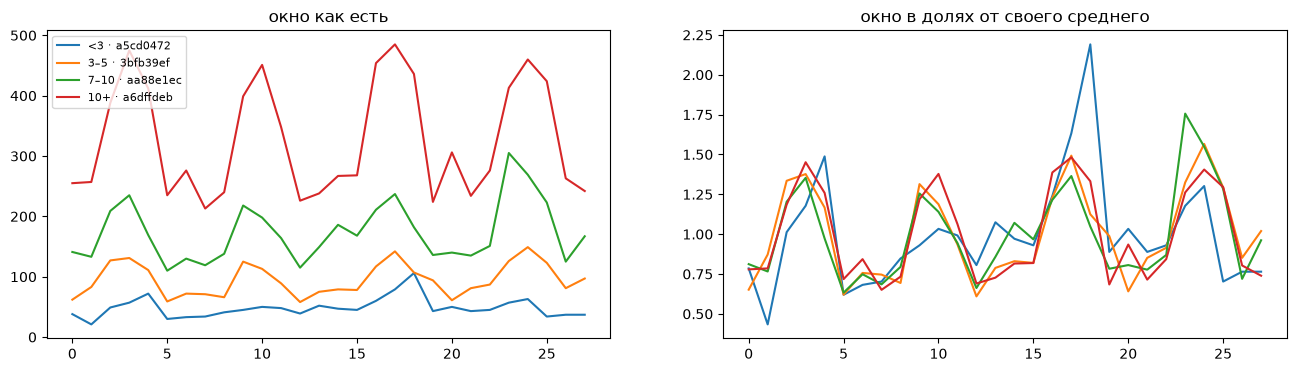

In [6]:
# 10 юнитов, по 2 из каждого размера (UnitSize); общий период — с 2026-04-01, как в главе о кластеризации
START = "2026-04-01"
units = pd.read_csv(f"{DATA_DIR}/units.csv")
facts = pd.read_csv(f"{DATA_DIR}/facts-by-date.csv", parse_dates=["CalendarDate"])
facts = facts[facts["CalendarDate"] >= START]
df_units = facts.rename(columns={"CalendarDate": "timestamp", "MaskedUnitId": "segment", "Fact": "target"})
ts_units = TSDataset(df_units, freq="D")
unit_size = units.set_index("MaskedUnitId")["UnitSize"]

# Окна по 4 недели с шагом в неделю; класс 1 — крупный юнит (7–10, 10+), 0 — маленький (<3, 3–5); 5–7 не берём
WINDOW, STEP = 28, 7
LABELS = {"<3": 0, "3–5": 0, "7–10": 1, "10+": 1}
windows = []
for segment in ts_units.segments:
    if unit_size[segment] not in LABELS:
        continue
    values = ts_units[:, segment, "target"].values
    for start in range(0, len(values) - WINDOW + 1, STEP):
        windows.append({"segment": segment, "unit_size": unit_size[segment], "values": values[start : start + WINDOW]})
windows = pd.DataFrame(windows)
x_units = list(windows["values"])
x_units_relative = [w / w.mean() for w in x_units]  # то же окно в долях от своего среднего: масштаба нет, форма осталась
y_units = windows["unit_size"].map(LABELS).values
print(f"дней: {len(ts_units.to_pandas())}, окон: {len(windows)}, по {len(windows) // windows['segment'].nunique()} на юнит")

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for segment in ["a5cd0472", "3bfb39ef", "aa88e1ec", "a6dffdeb"]:
    first = windows[windows["segment"] == segment].index[0]
    label = f"{unit_size[segment]} · {segment}"
    axes[0].plot(x_units[first], label=label)
    axes[1].plot(x_units_relative[first], label=label)
axes[0].set_title("окно как есть")
axes[1].set_title("окно в долях от своего среднего")
axes[0].legend(loc="upper left", fontsize=8)
save_fig(fig, "windows")

#### Выводы

- **144 окна:** по 18 у каждого из 8 юнитов.
- **Как есть окна различаются уровнем** — от ~50 до ~300 заказов в день.
- **В долях от своего среднего окна почти совпадают:** пики в пятницу–субботу у всех; у самого маленького юнита только больше случайных скачков.

### Шаг 2.2. Обучение и проверка

Фолд — это юниты целиком: окна одного юнита похожи друг на друга, и если они попадут и в обучение, и в проверку, классификатор просто узнает знакомый юнит. В каждом из 4 фолдов — один маленький и один крупный юнит. Три способа: tsfresh по окнам как есть, tsfresh по окнам в долях от среднего, WEASEL.

In [7]:
# Окна одного юнита похожи, поэтому фолд — это юниты целиком: в каждом один маленький и один крупный юнит
small = ["8a399130", "a5cd0472", "3bfb39ef", "9bb64107"]  # <3, <3, 3–5, 3–5
large = ["aa88e1ec", "d3319417", "70650540", "a6dffdeb"]  # 7–10, 7–10, 10+, 10+
fold_of = {segment: fold for fold, pair in enumerate(zip(small, large)) for segment in pair}
mask_units = windows["segment"].map(fold_of).values

units_proba = {
    "tsfresh": crossval("tsfresh", x_units, y_units, mask_units),
    "tsfresh_relative": crossval("tsfresh", x_units_relative, y_units, mask_units),
    "weasel": crossval("weasel", x_units, y_units, mask_units),
}
pd.DataFrame({name: scores(y_units, proba, mask_units) for name, proba in units_proba.items()}).T

,auc,accuracy
tsfresh,1.00,1.00
tsfresh_relative,0.67,0.58
weasel,0.59,0.57


In [8]:
# Средняя вероятность «крупный» по окнам каждого юнита — для способов, которые видят только форму
windows.assign(tsfresh_relative=units_proba["tsfresh_relative"], weasel=units_proba["weasel"]).groupby(
    ["unit_size", "segment"]
)[["tsfresh_relative", "weasel"]].mean().round(2).sort_index(key=lambda s: s.map({"<3": 0, "3–5": 1, "7–10": 2, "10+": 3}) if s.name == "unit_size" else s)

tsfresh_relative  weasel
unit_size segment                           
<3        8a399130              0.50    0.25
          a5cd0472              0.41    0.61
3–5       3bfb39ef              0.49    0.64
          9bb64107              0.55    0.38
7–10      aa88e1ec              0.52    0.52
          d3319417              0.48    0.61
10+       70650540              0.54    0.41
          a6dffdeb              0.54    0.70

#### Выводы

| способ | что видит | AUC | доля верных |
|---|---|---|---|
| `tsfresh` | уровень и разброс | **1.00** | **1.00** |
| `tsfresh_relative` | разброс и форму без уровня | 0.67 | 0.58 |
| `weasel` | только форму | 0.59 | 0.57 |

- **По окну как есть размер угадывается безошибочно:** размер юнита — это и есть объём заказов, а tsfresh видит среднее.
- **По форме — почти наугад:** без уровня AUC 0.59–0.67, доля верных ответов 0.57–0.58 при 0.5 у монетки.
- **Ни один юнит не узнаётся по форме:** средняя вероятность «крупный» по окнам каждого юнита — от 0.25 до 0.70, без связи с размером.
- **Это совпадает с кластеризацией:** недельный узор у юнитов всех размеров одинаковый, различает их только объём.